In [11]:
import argparse
import os
import time
import shutil

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torch.backends.cudnn as cudnn

    

import torchvision
import torchvision.transforms as transforms

import sys
sys.path.insert(0, os.path.abspath(".."))

from models import *

global best_prec
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("Using device:", device)
print('=> Building model...')
    
    
batch_size = 128

model_name = "resnet20"
#model = cifar10()
model = resnet20_cifar()

        

normalize = transforms.Normalize(mean=[0.491, 0.482, 0.447], std=[0.247, 0.243, 0.262])


train_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        normalize,
    ]))
trainloader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)


test_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transforms.Compose([
        transforms.ToTensor(),
        normalize,
    ]))

testloader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)


print_freq = 100 # every 100 batches, accuracy printed. Here, each batch includes "batch_size" data points
# CIFAR10 has 50,000 training data, and 10,000 validation data.

def train(trainloader, model, criterion, optimizer, epoch):
    batch_time = AverageMeter()   ## at the begining of each epoch, this should be reset
    data_time = AverageMeter()
    losses = AverageMeter()
    top1 = AverageMeter()

    model.train()

    end = time.time()  # measure current time
    
    for i, (input, target) in enumerate(trainloader):
        # measure data loading time
        data_time.update(time.time() - end)  # data loading time

        input, target = input.to(device), target.to(device)

        # compute output
        output = model(input)
        loss = criterion(output, target)

        # measure accuracy and record loss
        prec = accuracy(output, target)[0]
        losses.update(loss.item(), input.size(0))
        top1.update(prec.item(), input.size(0))

        # compute gradient and do SGD step
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # measure elapsed time
        batch_time.update(time.time() - end) # time spent to process one batch
        end = time.time()


        if i % print_freq == 0:
            print('Epoch: [{0}][{1}/{2}]\t'
                  'Time {batch_time.val:.3f} ({batch_time.avg:.3f})\t'
                  'Data {data_time.val:.3f} ({data_time.avg:.3f})\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec {top1.val:.3f}% ({top1.avg:.3f}%)'.format(
                   epoch, i, len(trainloader), batch_time=batch_time,
                   data_time=data_time, loss=losses, top1=top1))

            

def validate(val_loader, model, criterion ):
    batch_time = AverageMeter()
    losses = AverageMeter()
    top1 = AverageMeter()

    # switch to evaluate mode
    model.eval()

    end = time.time()
    with torch.no_grad():
        for i, (input, target) in enumerate(val_loader):
         
            input, target = input.to(device), target.to(device)

            # compute output
            output = model(input)
            loss = criterion(output, target)

            # measure accuracy and record loss
            prec = accuracy(output, target)[0]
            losses.update(loss.item(), input.size(0))
            top1.update(prec.item(), input.size(0))

            # measure elapsed time
            batch_time.update(time.time() - end)
            end = time.time()

            if i % print_freq == 0:  # This line shows how frequently print out the status. e.g., i%5 => every 5 batch, prints out
                print('Test: [{0}/{1}]\t'
                  'Time {batch_time.val:.3f} ({batch_time.avg:.3f})\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec {top1.val:.3f}% ({top1.avg:.3f}%)'.format(
                   i, len(val_loader), batch_time=batch_time, loss=losses,
                   top1=top1))

    print(' * Prec {top1.avg:.3f}% '.format(top1=top1))
    return top1.avg


def accuracy(output, target, topk=(1,5)):
    """Computes the precision@k for the specified values of k"""
    maxk = max(topk) # 5
    batch_size = target.size(0) # 128

    _, pred = output.topk(maxk, 1, True, True) # topk(k, dim=None, largest=True, sorted=True)
                                    # will output (max value, its index)
    pred = pred.t()               # transpose
    correct = pred.eq(target.view(1, -1).expand_as(pred))   # "-1": calculate automatically

    res = []
    for k in topk: # 1, 5
        correct_k = correct[:k].clone().resize_(k * batch_size).float().sum()
        res.append(correct_k.mul_(100.0 / batch_size))   # correct: size of [maxk, batch_size]
    return res


class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n    ## n is impact factor
        self.count += n
        self.avg = self.sum / self.count

        
def save_checkpoint(state, is_best, fdir):
    filepath = os.path.join(fdir, 'checkpoint.pth')
    torch.save(state, filepath)
    if is_best:
        shutil.copyfile(filepath, os.path.join(fdir, 'model_best.pth.tar'))


def adjust_learning_rate(optimizer, epoch):
    """For resnet, the lr starts from 0.1, and is divided by 10 at 80 and 120 epochs"""
    adjust_list = [80, 120]
    if epoch in adjust_list:
        for param_group in optimizer.param_groups:
            param_group['lr'] = param_group['lr'] * 0.1        

Using device: mps
=> Building model...


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.49392712..1.5658436].


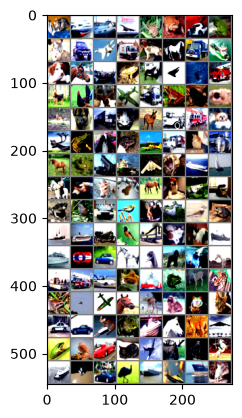

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# functions to show an image

def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# get some random training images
dataiter = iter(testloader)
images, labels = next(dataiter) ## If you run this line, the next data batch is called subsequently.

# show images
imshow(torchvision.utils.make_grid(images))


In [ ]:
# This cell is from the website

lr = 1e-1



weight_decay = 1e-4
epochs = 150
best_prec = 0

model = model.to(device)
criterion = nn.CrossEntropyLoss().to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
# weight decay: for regularization to prevent overfitting


if not os.path.exists('result'):
    os.makedirs('result')
    
fdir = 'result/'+str(model_name)

if not os.path.exists(fdir):
    os.makedirs(fdir)
        

for epoch in range(0, epochs):
    adjust_learning_rate(optimizer, epoch)

    train(trainloader, model, criterion, optimizer, epoch)
    
    # evaluate on test set
    print("Validation starts")
    prec = validate(testloader, model, criterion)

    # remember best precision and save checkpoint
    is_best = prec > best_prec
    best_prec = max(prec,best_prec)
    print('best acc: {:1f}'.format(best_prec))
    save_checkpoint({
        'epoch': epoch + 1,
        'state_dict': model.state_dict(),
        'best_prec': best_prec,
        'optimizer': optimizer.state_dict(),
    }, is_best, fdir)
    

In [13]:

fdir = 'result/'+str(model_name)+'/model_best.pth.tar'

checkpoint = torch.load(fdir)
model.load_state_dict(checkpoint['state_dict'])


criterion = nn.CrossEntropyLoss().to(device)

model.eval()
model.to(device)


prec = validate(testloader, model, criterion)


Test: [0/79]	Time 1.717 (1.717)	Loss 0.2031 (0.2031)	Prec 92.969% (92.969%)
 * Prec 91.740% 


In [14]:
import json

# load the quantization functions from [Code8] (only its first cell, not the demo cells)
code8 = json.load(open('../[Code8]_Weight_and_Activation_Quantization.ipynb'))
exec(''.join(code8['cells'][0]['source']))          # defines weight_quantization(), weight_quantize_fn(), act_quantization()


def choose_alpha(w, method):
    if method == 'max':
        return w.abs().max()
    k = float(method.split('_')[0])                     # e.g. '4_std' -> 4 * std(w)
    return k * w.std()

def quantize_conv_weights(model, w_bits, method):
    weight_quant = weight_quantize_fn(w_bit=w_bits)     # from [Code8]: 1 sign bit + (w_bits-1) magnitude bits
    with torch.no_grad():                               # in-place update of a parameter
        for layer in model.modules():
            if isinstance(layer, torch.nn.Conv2d):
                weight_quant.wgt_alpha = choose_alpha(layer.weight, method)
                layer.weight.copy_(weight_quant(layer.weight))

In [15]:
w_bits = 8
results_8bit = {}

for method in ['max', '3_std', '4_std']:
    model.load_state_dict(checkpoint['state_dict'])     # reload the float checkpoint
    quantize_conv_weights(model, w_bits, method)

    print('{}-bit weights, alpha = {}'.format(w_bits, method))
    results_8bit[method] = validate(testloader, model, criterion)

model.load_state_dict(checkpoint['state_dict'])         # back to float

print('\nfloat: {:.2f}%'.format(prec))
for method, acc in results_8bit.items():
    print('{}-bit, alpha = {:6s}: {:.2f}%'.format(w_bits, method, acc))

8-bit weights, alpha = max


<string>:61: DeprecationWarning: <class '__main__.weight_quantization.<locals>.uq'> should not be instantiated. Methods on autograd functions are all static, so you should invoke them on the class itself. Instantiating an autograd function will raise an error in a future version of PyTorch.


Test: [0/79]	Time 1.918 (1.918)	Loss 0.2031 (0.2031)	Prec 92.188% (92.188%)
 * Prec 91.720% 
8-bit weights, alpha = 3_std
Test: [0/79]	Time 1.593 (1.593)	Loss 0.3526 (0.3526)	Prec 88.281% (88.281%)
 * Prec 87.050% 
8-bit weights, alpha = 4_std
Test: [0/79]	Time 1.640 (1.640)	Loss 0.2148 (0.2148)	Prec 93.750% (93.750%)
 * Prec 91.020% 

float: 91.74%
8-bit, alpha = max   : 91.72%
8-bit, alpha = 3_std : 87.05%
8-bit, alpha = 4_std : 91.02%


In [16]:
w_bits = 4
results_4bit = {}

for method in ['max', '3_std', '4_std']:
    model.load_state_dict(checkpoint['state_dict'])     # reload the float checkpoint
    quantize_conv_weights(model, w_bits, method)

    print('{}-bit weights, alpha = {}'.format(w_bits, method))
    results_4bit[method] = validate(testloader, model, criterion)

model.load_state_dict(checkpoint['state_dict'])         # back to float

print('\nfloat: {:.2f}%'.format(prec))
for method, acc in results_4bit.items():
    print('{}-bit, alpha = {:6s}: {:.2f}%'.format(w_bits, method, acc))

4-bit weights, alpha = max


<string>:61: DeprecationWarning: <class '__main__.weight_quantization.<locals>.uq'> should not be instantiated. Methods on autograd functions are all static, so you should invoke them on the class itself. Instantiating an autograd function will raise an error in a future version of PyTorch.


Test: [0/79]	Time 1.678 (1.678)	Loss 0.5179 (0.5179)	Prec 89.062% (89.062%)
 * Prec 86.800% 
4-bit weights, alpha = 3_std
Test: [0/79]	Time 1.659 (1.659)	Loss 0.4761 (0.4761)	Prec 84.375% (84.375%)
 * Prec 85.280% 
4-bit weights, alpha = 4_std
Test: [0/79]	Time 1.621 (1.621)	Loss 0.2598 (0.2598)	Prec 91.406% (91.406%)
 * Prec 88.390% 

float: 91.74%
4-bit, alpha = max   : 86.80%
4-bit, alpha = 3_std : 85.28%
4-bit, alpha = 4_std : 88.39%


## Part II: Manual Calculation of Layers

In [ ]:
# Part II: capture intermediate activations with forward pre-hooks
acts = {}

def save_input(name):
    def hook(module, inp):
        # clone: the following inplace ReLU would otherwise overwrite the saved tensor
        acts[name] = inp[0].detach().clone()
    return hook

# layer1[0] = BasicBlock0, layer1[1] = BasicBlock1
print(model.layer1[0])
handles = [
    model.layer1[0].conv1.register_forward_pre_hook(save_input('block0_conv1')),
    model.layer1[1].conv1.register_forward_pre_hook(save_input('block1_conv1')),
]

images, labels = next(iter(testloader))
model.eval()
with torch.no_grad():
    model(images.to(device))

for h in handles:
    h.remove()


In [ ]:
# Manually reproduce BasicBlock0: conv1 -> bn1 -> relu -> conv2 -> bn2 -> (+ residual) -> relu
x = acts['block0_conv1'][0:1]    # one test image
ref = acts['block1_conv1'][0:1]
block = model.layer1[0]

with torch.no_grad():
    out = block.conv1(x)
    out = block.bn1(out)           # eval mode -> running stats
    out = F.relu(out)
    out = block.conv2(out)
    out = block.bn2(out)
    out = out + x                  # residual connection (no downsample in BasicBlock0)
    out = F.relu(out)

print('shape:', tuple(out.shape), 'vs reference', tuple(ref.shape))
print('max abs difference:', (out - ref).abs().max().item())
print('allclose:', torch.allclose(out, ref, atol=1e-5))